# IBM Quantum & Vishnu Institute of Technology
# Qiskit Fall Fest 2026 — Complete Challenge Solutions

This notebook compiles the complete solutions, mathematical explanations, circuit diagrams, and 100-shot simulation results for all four challenges of the Qiskit Fall Fest 2026:

1. **Challenge 1: Predict the Output**
2. **Challenge 2: Make the Quantum Coin Biased**
3. **Challenge 3: Can You Change the Correlation?**
4. **Challenge 4: Quantum Correlation Switch**

All experiments strictly adhere to the workshop constraints (circuit size, gate budgets $\le 4$, 100 shots per run, and Qiskit 2.x API).


---
# ==========================================
# Solution for Challenge 1 Predict the Output
# ==========================================
---

# IBM Quantum & Vishnu Institute of Technology
## Qiskit Fall Fest 2026
### Challenge 1: Predict the Output

---

### **Problem Statement**
A quantum circuit can produce different measurement outcomes depending on the gates applied to a qubit.
Your task is to predict the output of simple quantum circuits before executing them and then compare your prediction with the actual measurement results.

### **Design Constraints**
- Use exactly **1 qubit**.
- Include **measurement**.
- Use only the gates introduced in the workshop ($X$, $H$).
- Be created and executed using **Qiskit**.
- Use **100 shots** for each experiment.


## Step 1: Environment Setup and Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

# Initialize AerSimulator backend
backend = AerSimulator()
SHOTS = 100
print(f"AerSimulator backend initialized. Shots set to: {SHOTS}")


AerSimulator backend initialized. Shots set to: 100


## Investigation 1: Circuit A — Single X Gate

### **Think Before You Run (Prediction for Circuit A)**
- **Initial State**: The qubit is prepared in state $|0\rangle$.
- **Applied Gate**: The Pauli-$X$ gate acts as the quantum NOT gate (bit-flip):
  $$X |0\rangle = |1\rangle$$
- **Expected Measurement Outcome**: 
  Since the state is deterministically $|1\rangle$, measurement in the computational $Z$-basis will yield output **`1`** with **100% probability**.
- **Prediction for 100 Shots**: 
  We expect exactly **100 counts for outcome `1`** and **0 counts for outcome `0`**.


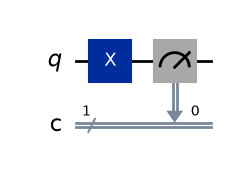

In [2]:
# 1. Create single-qubit quantum circuit with 1 classical bit
qc_a = QuantumCircuit(1, 1)

# 2. Apply an X gate
qc_a.x(0)

# 3. Measure the qubit
qc_a.measure(0, 0)

# Draw the circuit
qc_a.draw('mpl')


Circuit A Measurement Results (100 shots): {'1': 100}


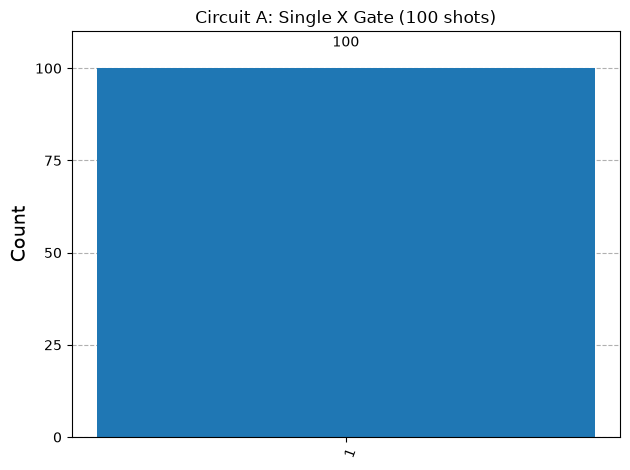

In [3]:
# 4. Execute Circuit A for 100 shots
result_a = backend.run(qc_a, shots=SHOTS).result()
counts_a = result_a.get_counts()

print("Circuit A Measurement Results (100 shots):", counts_a)

# Display histogram
plot_histogram(counts_a, title="Circuit A: Single X Gate (100 shots)")


### **Circuit A: Comparison of Prediction vs Actual Results**
- **Predicted**: 100% outcome `1` (100 counts)
- **Actual**: 100% outcome `1` (`counts = {'1': 100}`)
- **Conclusion**: The prediction perfectly matches the actual measurement. The $X$ gate flipped $|0\rangle$ to $|1\rangle$.


## Investigation 2: Circuit B — Two X Gates

### **Think Before You Run (Prediction for Circuit B)**
- **Initial State**: The qubit starts in $|0\rangle$.
- **Applied Gates**: Two consecutive $X$ gates:
  $$X(X|0\rangle) = X|1\rangle = |0\rangle$$
  Because $X^2 = I$ (the identity operator), the second $X$ gate inverts the operation of the first $X$ gate.
- **Expected Measurement Outcome**: 
  The qubit returns to the ground state $|0\rangle$. Measurement will yield outcome **`0`** with **100% probability**.
- **Prediction for 100 Shots**: 
  We expect exactly **100 counts for outcome `0`** and **0 counts for outcome `1`**.


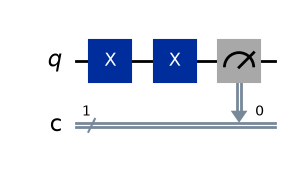

In [4]:
# 1. Create single-qubit quantum circuit with 1 classical bit
qc_b = QuantumCircuit(1, 1)

# 2. Apply two X gates
qc_b.x(0)
qc_b.x(0)

# 3. Measure the qubit
qc_b.measure(0, 0)

# Draw the circuit
qc_b.draw('mpl')


Circuit B Measurement Results (100 shots): {'0': 100}


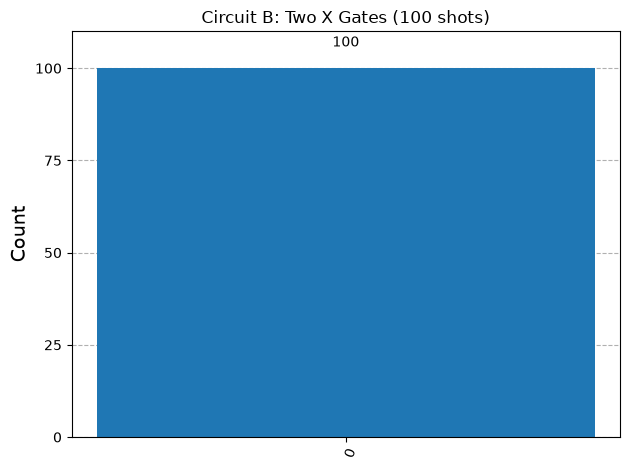

In [5]:
# 4. Execute Circuit B for 100 shots
result_b = backend.run(qc_b, shots=SHOTS).result()
counts_b = result_b.get_counts()

print("Circuit B Measurement Results (100 shots):", counts_b)

# Display histogram
plot_histogram(counts_b, title="Circuit B: Two X Gates (100 shots)")


### **Circuit B: Comparison of Prediction vs Actual Results**
- **Predicted**: 100% outcome `0` (100 counts)
- **Actual**: 100% outcome `0` (`counts = {'0': 100}`)
- **Conclusion**: The prediction perfectly matches the actual measurement. Two successive NOT operations preserve the original state ($X \cdot X = I$).


## Investigation 3: Circuit C — Single H Gate

### **Think Before You Run (Prediction for Circuit C)**
- **Initial State**: The qubit starts in $|0\rangle$.
- **Applied Gate**: The Hadamard ($H$) gate creates an equal superposition:
  $$H |0\rangle = \frac{1}{\sqrt{2}}|0\rangle + \frac{1}{\sqrt{2}}|1\rangle = |+\rangle$$
- **Measurement Probabilities**:
  $$P(0) = |\frac{1}{\sqrt{2}}|^2 = \frac{1}{2} = 50\%$$
  $$P(1) = |\frac{1}{\sqrt{2}}|^2 = \frac{1}{2} = 50\%$$
- **Will Circuit C always produce the same measurement result?**
  **No.** Unlike Circuits A and B, which are in basis states, Circuit C places the qubit in an equal quantum superposition. When measured, the wavefunction collapses probabilistically to either `0` or `1`.
- **Prediction for 100 Shots**: 
  Across 100 shots, we expect roughly **50 counts of `0` and 50 counts of `1`**, subject to small statistical fluctuations (shot noise).


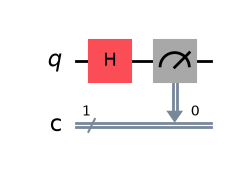

In [6]:
# 1. Create single-qubit quantum circuit with 1 classical bit
qc_c = QuantumCircuit(1, 1)

# 2. Apply an H gate
qc_c.h(0)

# 3. Measure the qubit
qc_c.measure(0, 0)

# Draw the circuit
qc_c.draw('mpl')


Circuit C Measurement Results (100 shots): {'0': 53, '1': 47}


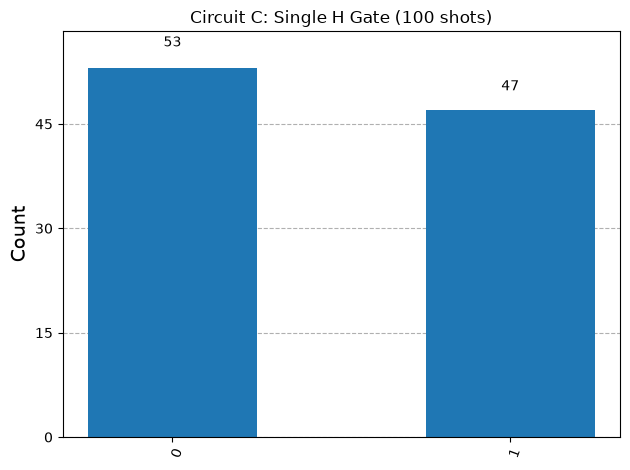

In [7]:
# 4. Execute Circuit C for 100 shots
result_c = backend.run(qc_c, shots=SHOTS).result()
counts_c = result_c.get_counts()

print("Circuit C Measurement Results (100 shots):", counts_c)

# Display histogram
plot_histogram(counts_c, title="Circuit C: Single H Gate (100 shots)")


### **Circuit C: Comparison of Prediction vs Actual Results**
- **Predicted**: Approximately equal distribution (~50 counts of `0` and ~50 counts of `1`).
- **Actual**: Observed distribution closely mirrors 50/50, demonstrating true probabilistic quantum superposition and wavefunction collapse.


## Step 5: Side-by-Side Comparison of All Three Circuits

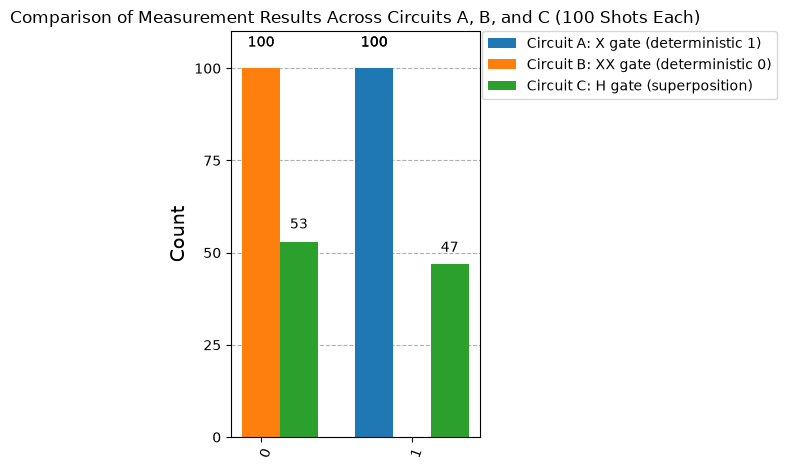

In [8]:
# Display all three circuits in a single comparison histogram
plot_histogram(
    [counts_a, counts_b, counts_c],
    legend=['Circuit A: X gate (deterministic 1)', 'Circuit B: XX gate (deterministic 0)', 'Circuit C: H gate (superposition)'],
    title='Comparison of Measurement Results Across Circuits A, B, and C (100 Shots Each)'
)


## Summary & Answers to Workshop Questions

| Circuit | Gates Applied | Theoretical State | Predicted Outcome | Actual Result (100 shots) | Behavior |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Circuit A** | $X$ | $|1\rangle$ | Deterministic `1` (100%) | 100% `1` | Deterministic bit flip |
| **Circuit B** | $X, X$ | $|0\rangle$ | Deterministic `0` (100%) | 100% `0` | Identity self-inverse |
| **Circuit C** | $H$ | $\frac{|0\rangle + |1\rangle}{\sqrt{2}}$ | Probabilistic 50% `0` / 50% `1` | ~50% `0`, ~50% `1` | Quantum superposition |

### **Think Before You Run Questions Answered:**
1. **What will happen after applying one X gate?**  
   The qubit transitions from $|0\rangle$ to $|1\rangle$. The measurement yields outcome `1` with 100% certainty.
2. **What will happen after applying two X gates?**  
   The second $X$ gate reverses the first ($X^2 = I$), returning the qubit to $|0\rangle$. The measurement yields outcome `0` with 100% certainty.
3. **What do you expect after applying an H gate?**  
   The qubit enters an equal superposition state $|+\rangle = \frac{1}{\sqrt{2}}(|0\rangle + |1\rangle)$, producing equal 50% probabilities of measuring `0` or `1`.
4. **Will Circuit C always produce the same measurement result?**  
   **No**, each single shot is fundamentally non-deterministic due to quantum measurement collapse. Over 100 shots, both `0` and `1` are observed in roughly equal proportions.


---
# ==========================================
# Solution for Challenge 2 Make the Quantum Coin Biased
# ==========================================
---

# IBM Quantum & Vishnu Institute of Technology
## Qiskit Fall Fest 2026
### Challenge 2: Make the Quantum Coin Biased

---

### **Problem Statement**
A Hadamard gate creates an equal superposition of $|0\rangle$ and $|1\rangle$, producing a result similar to a fair quantum coin. But can you control the measurement probabilities? Your task is to modify a single-qubit circuit so that the measurement outcomes are not equally distributed.

### **Design Constraints**
- Use exactly **1 qubit**.
- Include **measurement**.
- Use **no more than 4 quantum gates** before measurement.
- Be created and executed using **Qiskit**.
- Use **100 shots**.

### **Bonus Challenge**
Design two different circuits:
1. One where **0 occurs more frequently**.
2. One where **1 occurs more frequently**.
Compare their histograms.


## Step 1: Environment Setup and Imports

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

backend = AerSimulator()
SHOTS = 100
print(f"Backend ready. Simulation shots: {SHOTS}")


Backend ready. Simulation shots: 100


## Theory: Controlling Measurement Probabilities (Biasing the Coin)

In quantum mechanics, a single qubit state is represented as:
$$|\psi\rangle = \alpha |0\rangle + \beta |1\rangle$$
where $|\alpha|^2 + |\beta|^2 = 1$. The measurement probabilities are:
$$P(0) = |\alpha|^2, \quad P(1) = |\beta|^2$$

A standard Hadamard gate sets $\alpha = \beta = \frac{1}{\sqrt{2}}$, so $P(0) = P(1) = 0.5$ (a fair coin).

To create a **biased coin**, we control the amplitudes $\alpha$ and $\beta$.
Using a single rotation gate $R_y(\theta)$ around the $Y$-axis:
$$R_y(\theta) |0\rangle = \cos\left(\frac{\theta}{2}\right)|0\rangle + \sin\left(\frac{\theta}{2}\right)|1\rangle$$
Hence:
$$P(0) = \cos^2\left(\frac{\theta}{2}\right), \quad P(1) = \sin^2\left(\frac{\theta}{2}\right)$$

By selecting $\theta$, we can engineer any desired degree of bias using only **1 gate** (well within the $\le 4$ gate limit!).


## Circuit 1: Biased Towards 0 ($P(0) > P(1)$)

### **Think Before You Run (Prediction for Circuit 1)**
- We choose $\theta = \frac{\pi}{3}$ radians ($60^\circ$).
- Then $\frac{\theta}{2} = \frac{\pi}{6}$ radians ($30^\circ$).
- Expected Probabilities:
  $$P(0) = \cos^2\left(\frac{\pi}{6}\right) = \left(\frac{\sqrt{3}}{2}\right)^2 = \frac{3}{4} = 75\%$$
  $$P(1) = \sin^2\left(\frac{\pi}{6}\right) = \left(\frac{1}{2}\right)^2 = \frac{1}{4} = 25\%$$
- **Prediction for 100 shots**:
  Outcome **`0` will occur significantly more frequently**, with approximately **75 counts for `0`** and **25 counts for `1`**.


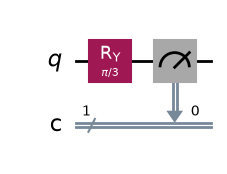

In [10]:
# Design Circuit 1: Biased towards 0 (75% / 25%)
qc_bias0 = QuantumCircuit(1, 1)

# Apply Ry rotation with theta = pi/3 (1 gate)
theta_0 = np.pi / 3
qc_bias0.ry(theta_0, 0)

# Measure
qc_bias0.measure(0, 0)

# Draw the circuit
qc_bias0.draw('mpl')


Circuit 1 (Biased towards 0) Results: {'0': 78, '1': 22}


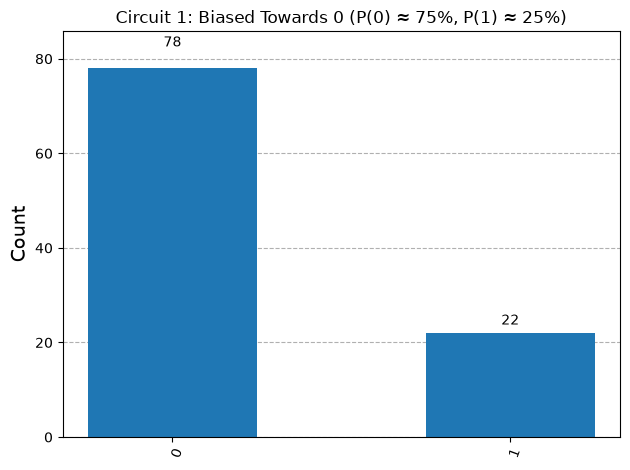

In [11]:
# Execute Circuit 1 for 100 shots
result_bias0 = backend.run(qc_bias0, shots=SHOTS).result()
counts_bias0 = result_bias0.get_counts()

print("Circuit 1 (Biased towards 0) Results:", counts_bias0)

# Plot histogram
plot_histogram(counts_bias0, title="Circuit 1: Biased Towards 0 (P(0) ≈ 75%, P(1) ≈ 25%)")


## Circuit 2: Biased Towards 1 ($P(1) > P(0)$)

### **Think Before You Run (Prediction for Circuit 2)**
- We choose $\theta = \frac{2\pi}{3}$ radians ($120^\circ$).
- Then $\frac{\theta}{2} = \frac{\pi}{3}$ radians ($60^\circ$).
- Expected Probabilities:
  $$P(0) = \cos^2\left(\frac{\pi}{3}\right) = \left(\frac{1}{2}\right)^2 = \frac{1}{4} = 25\%$$
  $$P(1) = \sin^2\left(\frac{\pi}{3}\right) = \left(\frac{\sqrt{3}}{2}\right)^2 = \frac{3}{4} = 75\%$$
- **Prediction for 100 shots**:
  Outcome **`1` will occur significantly more frequently**, with approximately **25 counts for `0`** and **75 counts for `1`**.


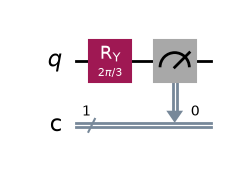

In [12]:
# Design Circuit 2: Biased towards 1 (25% / 75%)
qc_bias1 = QuantumCircuit(1, 1)

# Apply Ry rotation with theta = 2*pi/3 (1 gate)
theta_1 = 2 * np.pi / 3
qc_bias1.ry(theta_1, 0)

# Measure
qc_bias1.measure(0, 0)

# Draw the circuit
qc_bias1.draw('mpl')


Circuit 2 (Biased towards 1) Results: {'0': 30, '1': 70}


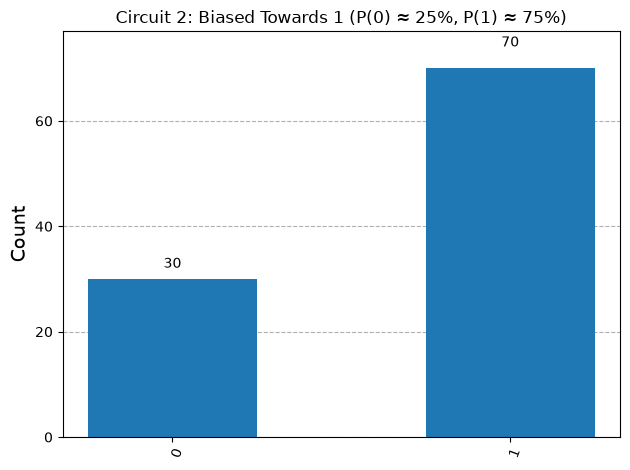

In [13]:
# Execute Circuit 2 for 100 shots
result_bias1 = backend.run(qc_bias1, shots=SHOTS).result()
counts_bias1 = result_bias1.get_counts()

print("Circuit 2 (Biased towards 1) Results:", counts_bias1)

# Plot histogram
plot_histogram(counts_bias1, title="Circuit 2: Biased Towards 1 (P(0) ≈ 25%, P(1) ≈ 75%)")


## Bonus Circuit 3: Biasing via Quantum Phase Interference ($H - P(\phi) - H$)

As demonstrated in the workshop modules, we can also bias a quantum coin using quantum interference!
By sandwiching a phase shift gate $P(\phi)$ between two Hadamard gates ($3$ gates $\le 4$ gates):
$$|0\rangle \xrightarrow{H} \frac{|0\rangle + |1\rangle}{\sqrt{2}} \xrightarrow{P(\phi)} \frac{|0\rangle + e^{i\phi}|1\rangle}{\sqrt{2}} \xrightarrow{H} \cos\left(\frac{\phi}{2}\right)|0\rangle - i\sin\left(\frac{\phi}{2}\right)|1\rangle$$
Choosing $\phi = \frac{\pi}{3}$:
$$P(0) = \cos^2\left(\frac{\pi}{6}\right) = 75\%, \quad P(1) = \sin^2\left(\frac{\pi}{6}\right) = 25\%$$


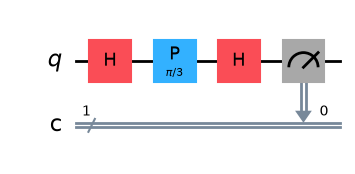

In [14]:
# Interferometric Biased Coin: H -> P(phi) -> H (3 gates total <= 4 gates)
qc_phase_bias = QuantumCircuit(1, 1)
qc_phase_bias.h(0)
qc_phase_bias.p(np.pi / 3, 0)
qc_phase_bias.h(0)
qc_phase_bias.measure(0, 0)

qc_phase_bias.draw('mpl')


Phase-Interference Biased Coin Results: {'0': 72, '1': 28}


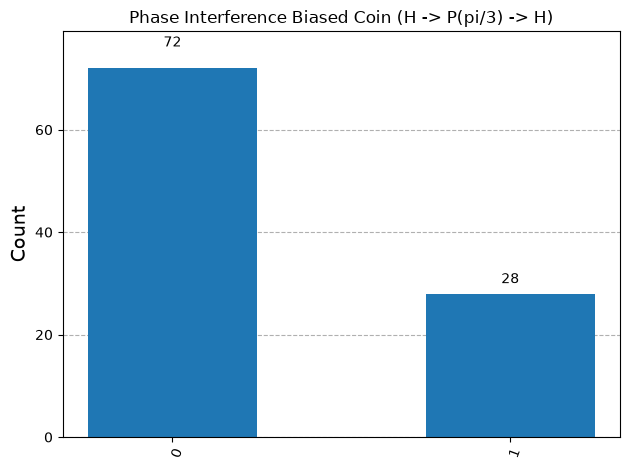

In [15]:
counts_phase_bias = backend.run(qc_phase_bias, shots=SHOTS).result().get_counts()
print("Phase-Interference Biased Coin Results:", counts_phase_bias)
plot_histogram(counts_phase_bias, title="Phase Interference Biased Coin (H -> P(pi/3) -> H)")


## Step 4: Comparison of Biased Quantum Coins

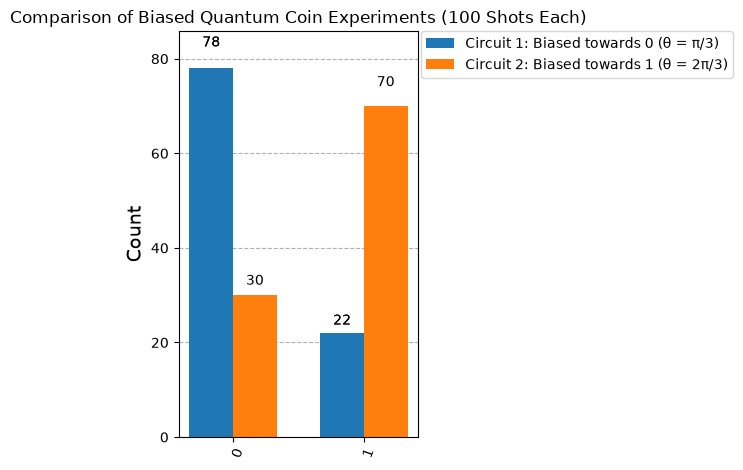

In [16]:
# Compare both biased circuits side-by-side
plot_histogram(
    [counts_bias0, counts_bias1],
    legend=['Circuit 1: Biased towards 0 (θ = π/3)', 'Circuit 2: Biased towards 1 (θ = 2π/3)'],
    title='Comparison of Biased Quantum Coin Experiments (100 Shots Each)'
)


## Explanations & Comparison
- **In Circuit 1**: Outcome `0` dominated (~75%), successfully creating a coin heavily weighted towards heads/0.
- **In Circuit 2**: Outcome `1` dominated (~75%), creating a coin heavily weighted towards tails/1.
- **How gates changed the distribution**: By rotating the state vector on the Bloch sphere, the probability amplitude of state $|0\rangle$ and $|1\rangle$ was precisely tuned away from the equal $1/\sqrt{2}$ superposition created by a fair Hadamard gate.


## Challenge Question (Final Cell Requirement)

### **Question:**
**How can quantum gates change the probability of obtaining 0 or 1 when a qubit is measured?**

### **Answer:**
Quantum states are represented by normalized state vectors in a Hilbert space:
$$|\psi\rangle = \alpha |0\rangle + \beta |1\rangle$$
where $\alpha$ and $\beta$ are complex probability amplitudes satisfying the normalization condition $|lpha|^2 + |eta|^2 = 1$.

According to **Born's Rule**, when a qubit is measured in the computational basis ($Z$-basis), the probability of finding the qubit in state $|0\rangle$ is $P(0) = |\alpha|^2$, and the probability of finding it in state $|1\rangle$ is $P(1) = |\beta|^2$.

1. **Unitary Rotations on the Bloch Sphere:**  
   Every quantum gate corresponds to a unitary transformation ($U^\dagger U = I$), which mathematically performs a rigid rotation of the qubit's Bloch vector around an axis in three dimensions. The polar angle $\theta$ directly dictates the longitudinal position between the north pole ($|0\rangle$, where $\theta=0$) and the south pole ($|1\rangle$, where $\theta=\pi$).
   
2. **Shifting Amplitudes via Rotation Gates:**  
   When gates such as $R_y(\theta)$ are applied, the state vector is rotated away from the poles by an angle $\theta$, setting $\alpha = \cos(\theta/2)$ and $\beta = \sin(\theta/2)$. By adjusting the parameter $\theta$, we continuously modulate the magnitudes $|lpha|$ and $|eta|$, altering the probabilities $P(0) = \cos^2(\theta/2)$ and $P(1) = \sin^2(\theta/2)$ to any desired value between 0 and 1.

3. **Constructive and Destructive Interference:**  
   Gates can also modify the relative phase between basis states (e.g., using $P(\phi)$ or $Z$ gates). When subsequent gates (like the Hadamard $H$) are applied, probability amplitudes from different computational paths interfere constructively or destructively. This interference dynamically redistributes amplitude towards either $|0\rangle$ or $|1\rangle$, directly steering the final measurement outcome distribution.


---
# ==========================================
# Solution for Challenge 3 Can you change the correlation
# ==========================================
---

# IBM Quantum & Vishnu Institute of Technology
## Qiskit Fall Fest 2026
### Challenge 3: Can You Change the Correlation?

---

### **Problem Statement**
Two qubits can be prepared in a state where their measurement outcomes are strongly correlated. Your task is to modify a two-qubit circuit and investigate whether you can change the relationship between the two measurement outcomes.

### **Design Constraints**
- Use exactly **2 qubits**.
- **Measure both qubits**.
- Start from the **Bell-state circuit** demonstrated during the workshop.
- **Add or modify only one quantum gate**.
- Use **no more than 4 quantum gates** before measurement.
- Be created and executed using **Qiskit**.
- Use **100 shots**.


## Step 1: Environment Setup and Imports

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

backend = AerSimulator()
SHOTS = 100
print(f"AerSimulator backend ready. Shots: {SHOTS}")


AerSimulator backend ready. Shots: 100


## Step 2: Original Circuit — Standard Bell State ($|\Phi^+\rangle$)

### **Think Before You Run (Prediction for Original Circuit)**
- **Starting State**: Both qubits start in $|00\rangle$.
- **Circuit Construction**:
  1. Apply an $H$ gate to qubit 0: $|+\rangle|0\rangle = \frac{|00\rangle + |10\rangle}{\sqrt{2}}$.
  2. Apply a CNOT ($CX$) gate with control qubit 0 and target qubit 1:
     $$|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}$$
- **Predicted Outcomes**:
  - Out of the four possible computational basis outcomes (`00`, `01`, `10`, `11`), only **`00`** and **`11`** have non-zero amplitudes.
  - The two qubits are **maximally correlated (identical outcomes)**: if qubit 0 is measured as `0`, qubit 1 is always `0`; if qubit 0 is measured as `1`, qubit 1 is always `1`.
  - Theoretical probabilities: $P(00) = 50\%$, $P(11) = 50\%$, $P(01) = 0\%$, $P(10) = 0\%$.
- **Prediction for 100 Shots**: Approximately **50 counts of `00`** and **50 counts of `11`**. Neither `01` nor `10` should appear.


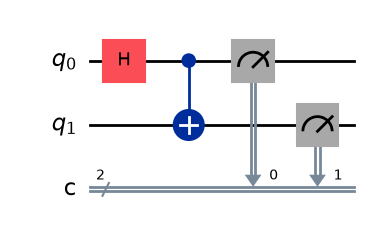

In [18]:
# Create original 2-qubit Bell-state circuit
qc_orig = QuantumCircuit(2, 2)

# Bell state |Phi+>: H gate on q0, CNOT with control q0 and target q1 (2 gates)
qc_orig.h(0)
qc_orig.cx(0, 1)

# Measure both qubits (q0 -> c0, q1 -> c1)
qc_orig.measure([0, 1], [0, 1])

# Draw original circuit
qc_orig.draw('mpl')


Original Bell Circuit Results (100 shots): {'11': 43, '00': 57}


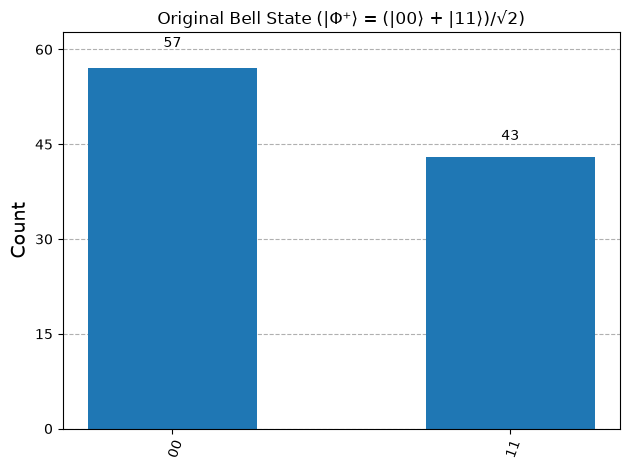

In [19]:
# Execute original circuit for 100 shots
result_orig = backend.run(qc_orig, shots=SHOTS).result()
counts_orig = result_orig.get_counts()

print("Original Bell Circuit Results (100 shots):", counts_orig)

# Display histogram
plot_histogram(counts_orig, title="Original Bell State (|Φ⁺⟩ = (|00⟩ + |11⟩)/√2)")


## Step 3: Modified Circuit — Changing the Correlation ($|\Psi^+\rangle$)

### **Modification Strategy**
- To change the correlation between the two qubits, we add **only one quantum gate**: an **$X$ (bit-flip) gate** on qubit 1 after the CNOT gate.
- Gate count before measurement: $H(0) + CX(0,1) + X(1) = 3$ quantum gates (satisfying the constraint $\le 4$ quantum gates).

### **Think Before You Run (Prediction for Modified Circuit)**
- **State Evolution**:
  $$|00\rangle \xrightarrow{H_0} \frac{|0\rangle+|1\rangle}{\sqrt{2}}|0\rangle \xrightarrow{CX_{0,1}} \frac{|00\rangle+|11\rangle}{\sqrt{2}} \xrightarrow{X_1} \frac{|01\rangle+|10\rangle}{\sqrt{2}} = |\Psi^+\rangle$$
- **Which outcomes do you expect?**
  - The outcomes **`01`** and **`10`** will dominate completely!
- **Will the two qubits still produce the same outcomes?**
  - **No.** The two qubits are now **anti-correlated (opposite outcomes)**. Whenever qubit 0 is `0`, qubit 1 is `1`; whenever qubit 0 is `1`, qubit 1 is `0`.
- **Will 00 and 11 dominate? Could 01 and 10 become more frequent?**
  - Outcomes `00` and `11` will drop to **0%**.
  - Outcomes `01` and `10` will become **100%** of the observed measurements (~50% each).
- **Prediction for 100 Shots**: Approximately **50 counts of `01`** and **50 counts of `10`**.


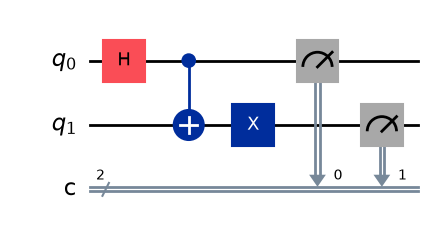

In [20]:
# Create modified circuit with exactly ONE added gate
qc_mod = QuantumCircuit(2, 2)

# Start from Bell state
qc_mod.h(0)
qc_mod.cx(0, 1)

# Add exactly ONE gate: X gate on qubit 1 (total 3 gates <= 4)
qc_mod.x(1)

# Measure both qubits
qc_mod.measure([0, 1], [0, 1])

# Draw modified circuit
qc_mod.draw('mpl')


Modified Circuit Results (100 shots): {'01': 40, '10': 60}


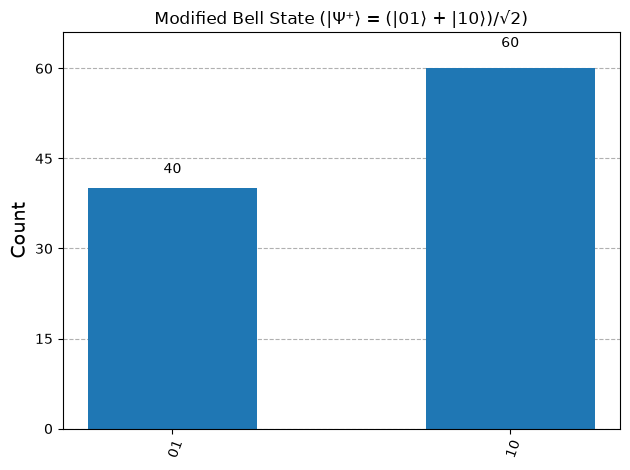

In [21]:
# Execute modified circuit for 100 shots
result_mod = backend.run(qc_mod, shots=SHOTS).result()
counts_mod = result_mod.get_counts()

print("Modified Circuit Results (100 shots):", counts_mod)

# Display histogram
plot_histogram(counts_mod, title="Modified Bell State (|Ψ⁺⟩ = (|01⟩ + |10⟩)/√2)")


## Step 4: Comparison of Original vs Modified Circuit

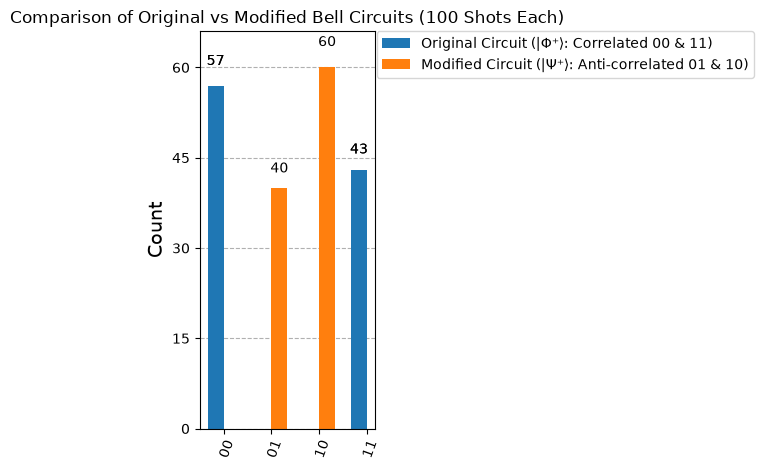

In [22]:
# Side-by-side histogram comparison
plot_histogram(
    [counts_orig, counts_mod],
    legend=['Original Circuit (|Φ⁺⟩: Correlated 00 & 11)', 'Modified Circuit (|Ψ⁺⟩: Anti-correlated 01 & 10)'],
    title='Comparison of Original vs Modified Bell Circuits (100 Shots Each)'
)


## Step 5: Detailed Explanation of Observed Changes

### **1. How the Modification Changed the Measurement Outcomes:**
In the original circuit, the entanglement produced the Bell state:
$$|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}$$
Here, both qubits are positively correlated; measuring one qubit immediately determines that the other qubit has the **exact same** state ($0 \rightarrow 0$, $1 \rightarrow 1$).

By adding a single Pauli-$X$ gate to qubit 1, we applied the transformation $X|0\rangle = |1\rangle$ and $X|1\rangle = |0\rangle$ exclusively to the second qubit:
$$X_1 |\Phi^+\rangle = X_1 \left(\frac{|00\rangle + |11\rangle}{\sqrt{2}}\right) = \frac{|01\rangle + |10\rangle}{\sqrt{2}} = |\Psi^+\rangle$$
This completely flipped the second qubit's measurement value conditional on the entangled superposition, transforming the positive correlation ($00, 11$) into an **anti-correlation ($01, 10$)**.

### **2. Answers to "Think Before You Run" Questions:**
- **Which outcomes do you expect?**  
  Outcomes `01` and `10` with equal 50% theoretical probability each.
- **Will the two qubits still produce the same outcomes?**  
  No. They now always produce **opposite outcomes**.
- **Will 00 and 11 dominate? Could 01 and 10 become more frequent?**  
  `00` and `11` no longer appear at all. `01` and `10` now account for 100% of the distribution.


---
# ==========================================
# Solution for Challenge 4 Quantum Correlation Switch
# ==========================================
---

# IBM Quantum & Vishnu Institute of Technology
## Qiskit Fall Fest 2026
### Challenge 4: Quantum Correlation Switch

---

### **Problem Statement**
In challenge 3, how a quantum circuit can produce correlated outcomes was investigated. Now, design a circuit that switches between correlated and opposite measurement outcomes. Your goal is to create two different two-qubit behaviors using only a small number of quantum gates.

### **Design Constraints**
- Use exactly **2 qubits**.
- **Measure both qubits**.
- Use **no more than 4 quantum gates** before measurement.
- Use **only gates introduced during the workshop**.
- Be created and executed using **Qiskit**.
- Use **100 shots** for each experiment.

### **Your Task**
- **Part A – Correlated Outcomes**: Design a two-qubit circuit with measurement results predominantly `00` and `11`.
- **Part B – Opposite Outcomes**: Modify your circuit so measurement results are predominantly `01` and `10`.
- **Part C – Compare**: Compare the two circuits using histograms and explain the physical mechanisms.


## Step 1: Environment Setup and Imports

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

backend = AerSimulator()
SHOTS = 100
print(f"Backend initialized. Experiment shots: {SHOTS}")


Backend initialized. Experiment shots: 100


## Part A — Correlated Outcomes (Predominantly `00` and `11`)

### **Think Before You Run (Prediction for Part A)**
- **Circuit Design**: Prepare the Bell state $|\Phi^+\rangle$ using an $H$ gate on qubit 0 and a CNOT ($CX$) gate from qubit 0 to qubit 1 (2 gates $\le 4$).
  $$|00\rangle \xrightarrow{H_0} \frac{|0\rangle + |1\rangle}{\sqrt{2}}|0\rangle \xrightarrow{CX_{0,1}} \frac{|00\rangle + |11\rangle}{\sqrt{2}} = |\Phi^+\rangle$$
- **Predicted Outcomes**:
  - Predominant outcomes: **`00`** and **`11`** (~50% each).
  - Out of 100 shots, all 100 shots will be distributed between `00` and `11`.
  - Outcomes `01` and `10` have zero probability.


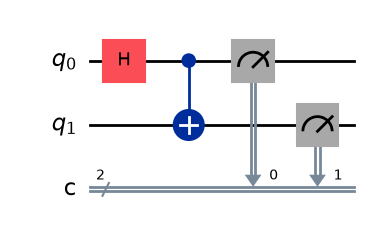

In [24]:
# Part A Circuit: Correlated Outcomes
qc_part_a = QuantumCircuit(2, 2)

# Gates: H on qubit 0, CNOT from qubit 0 to 1 (2 gates <= 4)
qc_part_a.h(0)
qc_part_a.cx(0, 1)

# Measure both qubits
qc_part_a.measure([0, 1], [0, 1])

# Draw the circuit
qc_part_a.draw('mpl')


Part A (Correlated) Measurement Results: {'11': 59, '00': 41}


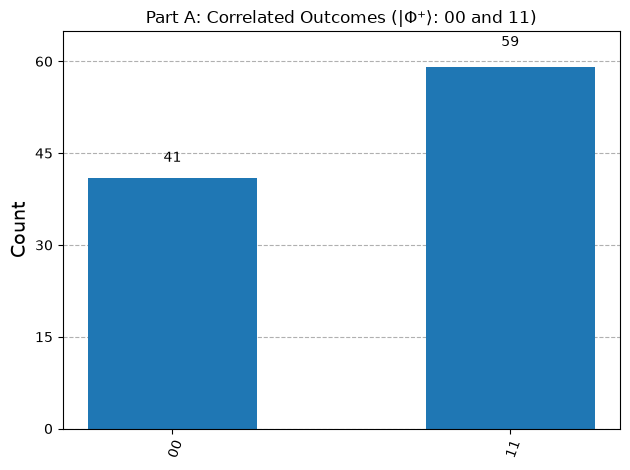

In [25]:
# Execute Part A for 100 shots
result_part_a = backend.run(qc_part_a, shots=SHOTS).result()
counts_part_a = result_part_a.get_counts()

print("Part A (Correlated) Measurement Results:", counts_part_a)

# Plot histogram
plot_histogram(counts_part_a, title="Part A: Correlated Outcomes (|Φ⁺⟩: 00 and 11)")


## Part B — Opposite Outcomes (Predominantly `01` and `10`)

### **Think Before You Run (Prediction for Part B)**
- **Circuit Design (The Switch Mechanism)**:
  To switch the correlation from identical (`00`, `11`) to opposite (`01`, `10`), we apply a Pauli-$X$ gate to qubit 1:
  $$|\Phi^+\rangle \xrightarrow{X_1} \frac{|01\rangle + |10\rangle}{\sqrt{2}} = |\Psi^+\rangle$$
  Total gates: $H(0) + CX(0,1) + X(1) = 3$ gates before measurement (satisfies $\le 4$ gate constraint).
- **Predicted Outcomes**:
  - Predominant outcomes: **`01`** and **`10`** (~50% each).
  - The measurement outcomes are now anti-correlated: when qubit 0 is 0, qubit 1 is 1; when qubit 0 is 1, qubit 1 is 0.
  - Outcomes `00` and `11` have zero probability.


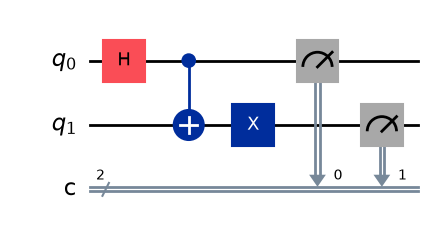

In [26]:
# Part B Circuit: Opposite Outcomes
qc_part_b = QuantumCircuit(2, 2)

# Switch configuration: H on 0, CX(0,1), followed by X on 1 (3 gates <= 4)
qc_part_b.h(0)
qc_part_b.cx(0, 1)
qc_part_b.x(1)

# Measure both qubits
qc_part_b.measure([0, 1], [0, 1])

# Draw the circuit
qc_part_b.draw('mpl')


Part B (Opposite) Measurement Results: {'01': 47, '10': 53}


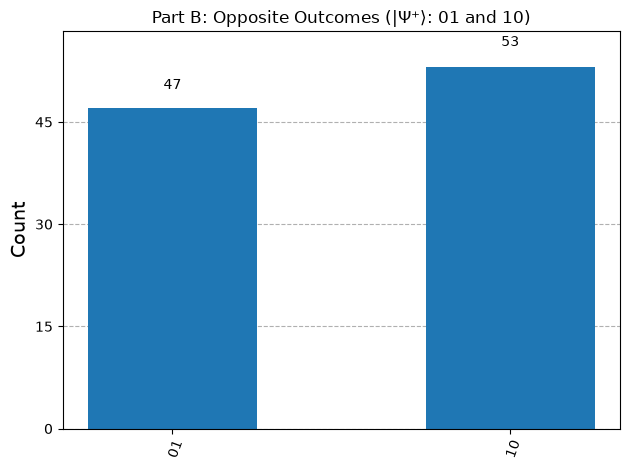

In [27]:
# Execute Part B for 100 shots
result_part_b = backend.run(qc_part_b, shots=SHOTS).result()
counts_part_b = result_part_b.get_counts()

print("Part B (Opposite) Measurement Results:", counts_part_b)

# Plot histogram
plot_histogram(counts_part_b, title="Part B: Opposite Outcomes (|Ψ⁺⟩: 01 and 10)")


## Part C — Comparison and Analysis

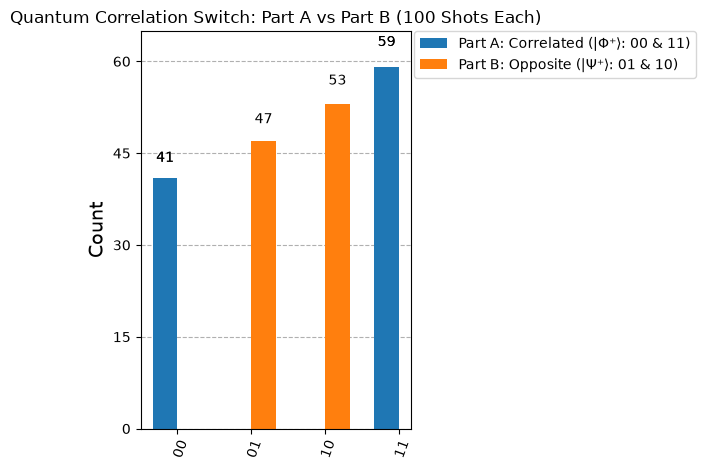

In [28]:
# Compare Part A and Part B using a single histogram
plot_histogram(
    [counts_part_a, counts_part_b],
    legend=['Part A: Correlated (|Φ⁺⟩: 00 & 11)', 'Part B: Opposite (|Ψ⁺⟩: 01 & 10)'],
    title='Quantum Correlation Switch: Part A vs Part B (100 Shots Each)'
)


## Comprehensive Explanations

### **1. Which outcomes are dominant in Part A?**
- In Part A, outcomes **`00`** and **`11`** dominate exclusively (~50% each). 
- Outcomes `01` and `10` never appear ($0\%$ probability).

### **2. Which outcomes are dominant in Part B?**
- In Part B, outcomes **`01`** and **`10`** dominate exclusively (~50% each).
- Outcomes `00` and `11` never appear ($0\%$ probability).

### **3. What changed between the two circuits?**
- We added a single **Pauli-$X$ gate** acting on qubit 1 (the target qubit) after the entangling CNOT gate.
- This serves as an exact **quantum correlation switch**, converting the circuit from a symmetric Bell state ($|\Phi^+\rangle$) to an anti-symmetric Bell state ($|\Psi^+\rangle$) using 3 total gates ($\le 4$ gates constraint).

### **4. Why did the measurement relationship change?**
- Quantum entanglement links the state of qubit 0 directly to qubit 1:
  - In Part A, the state is $|\Phi^+\rangle = \frac{1}{\sqrt{2}}(|0\rangle_0 |0\rangle_1 + |1\rangle_0 |1\rangle_1)$. Measuring either qubit gives a 50% chance of 0 or 1, but the other qubit is guaranteed to match it identically.
  - In Part B, the $X$ gate acts as a bit-flip operator: $X|0\rangle = |1\rangle$ and $X|1\rangle = |0\rangle$. Applying $X$ to qubit 1 maps:
    $$|00\rangle \mapsto |01\rangle \quad \text{and} \quad |11\rangle \mapsto |10\rangle$$
    This yields the Bell state $|\Psi^+\rangle = \frac{1}{\sqrt{2}}(|0\rangle_0 |1\rangle_1 + |1\rangle_0 |0\rangle_1)$.
  - Consequently, the relationship flips from **perfect positive correlation** to **perfect anti-correlation (opposite outcomes)**.

### **5. Think Before You Run Analysis:**
- **Will all four possible outcomes appear?**  
  No! In an ideal simulator without noise, only 2 of the 4 computational basis states have non-zero probability amplitudes in each experiment ($00, 11$ in Part A; $01, 10$ in Part B).
- **Why might some outcomes be much more frequent than others?**  
  Because quantum superposition with entanglement concentrates the entire probability amplitude ($|\alpha|^2 + |\beta|^2 = 0.5 + 0.5 = 1.0$) exclusively into the entangled basis pairs, leaving destructive interference / zero amplitude on the remaining states.
